# Context and thinking tokens in a small LLM

A support desk receives thousands of messages a day. Each message has to reach the right team. In this assignment you turn Qwen3-0.6B, a small instruction-tuned language model, into a router. It reads a customer message and answers with one of 27 intents in JSON. You measure how many tokens it uses for each message.

The first part is about the tokens that go into the model. You show it labeled examples before each message. You measure how accuracy, prompt length, time and memory change as the number of examples grows from none to hundreds. You then fine-tune the model with LoRA so that it needs no examples. You compare prompting with fine-tuning. Finally, you hide the message inside a long inbox of other messages. For the base model and the fine-tuned one, you measure accuracy when the message is at the start, in the middle and at the end.

The second part is about the tokens that come out before the answer. Qwen3 can write its reasoning in a `<think>` block and then answer. You measure whether reasoning helps on this classification task and how many generated tokens and how much time it uses. You also test the router you fine-tuned in the first part, whose training data contained no reasoning.

Before you change anything, all cells run from top to bottom and produce the baseline. The baseline uses no few-shot examples, a single message instead of an inbox, and an answer with the reasoning still attached. The questions at the end of each part are graded on what you measure and how you explain it.

In [1]:
import sys

if "google.colab" in sys.modules:
    %pip install -q "transformers>=4.51" "trl>=0.19" peft datasets accelerate

In [2]:
import os
import warnings

import datasets
import transformers

os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
warnings.filterwarnings("ignore")
transformers.utils.logging.set_verbosity_error()
transformers.utils.logging.disable_progress_bar()
datasets.disable_progress_bars()

In [3]:
import json
import math
import random
import re
import time
from collections import Counter, defaultdict

import matplotlib.pyplot as plt
import numpy as np
import torch
from datasets import Dataset, load_dataset
from transformers import AutoModelForCausalLM, AutoTokenizer

device = "cuda" if torch.cuda.is_available() else "cpu"
BF16 = torch.cuda.is_available() and torch.cuda.is_bf16_supported()
print(f"[INFO] device: {device}, bfloat16: {BF16}")
if device == "cuda":
    print(f"[INFO] GPU: {torch.cuda.get_device_name(0)}")

[INFO] device: cuda, bfloat16: True
[INFO] GPU: NVIDIA A100-SXM4-80GB


## Settings

Keep the defaults for the graded run.

In [4]:
MODEL_ID = "Qwen/Qwen3-0.6B"
SEED = 0
TEST_PER_INTENT = 10  # 270 test messages
torch.manual_seed(SEED)

## The data

The [Bitext customer support data set](https://huggingface.co/datasets/bitext/Bitext-customer-support-llm-chatbot-training-dataset) has 26,872 messages that customers might send to a support desk. Each message has one of 27 *intent* labels, such as `cancel_order` or `track_refund`. The intents fall into 11 categories. The messages are synthetic and use placeholders such as `{{Order Number}}`. The `flags` column marks how each message is phrased, for example `B` for basic syntax and `Z` for typos.

The cell holds out 10 messages per intent, 270 in all, as the test set. Every measurement in this assignment uses this test set or a fixed part of it. The remaining messages are the pool you draw training examples and few-shot examples from.

In [5]:
raw = load_dataset("bitext/Bitext-customer-support-llm-chatbot-training-dataset", split="train")
INTENTS = sorted(set(raw["intent"]))
print(f"[INFO] {len(raw):,} messages, {len(INTENTS)} intents")

rng = random.Random(SEED)
by_intent = defaultdict(list)
for row in raw:
    by_intent[row["intent"]].append({"text": row["instruction"], "intent": row["intent"], "flags": row["flags"]})
TEST, POOL = [], defaultdict(list)
for intent in INTENTS:
    rows = by_intent[intent][:]
    rng.shuffle(rows)
    TEST += rows[:TEST_PER_INTENT]
    POOL[intent] = rows[TEST_PER_INTENT:]
print(f"[INFO] test set: {len(TEST)} messages; pool: {sum(len(v) for v in POOL.values()):,} messages")
print(f"[INFO] example: {TEST[0]['text']!r} -> {TEST[0]['intent']}")

[INFO] 26,872 messages, 27 intents
[INFO] test set: 270 messages; pool: 26,602 messages
[INFO] example: 'can you help me cancelling purchase {{Order Number}}?' -> cancel_order


## The model and the router prompt

Qwen3-0.6B is a 0.6-billion-parameter instruction-tuned model with a context window of 32,768 tokens. The router prompt puts the list of allowed intents in the system message and the customer message in the user turn. It asks the model to return JSON. Qwen3 can reason in a `<think>` block before it answers; `enable_thinking=False` turns that off, and this assignment keeps it off.

`route` generates answers for a batch of prompts. `score` parses the answers. An answer counts as valid when it contains a JSON object with an `intent` field, and as correct when that field is the right intent.

In [6]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
tokenizer.padding_side = "left"  # generation continues from the right end of each prompt


def load_model(path=MODEL_ID):
    m = AutoModelForCausalLM.from_pretrained(path, dtype=torch.bfloat16 if BF16 else torch.float16)
    return m.to(device).eval()


def system_prompt(labels):
    return ("You route customer support messages. Choose exactly one intent from this list:\n"
            + ", ".join(labels)
            + '\nAnswer with JSON only, in the form {"intent": "<intent>"}.')


def build_prompt(text, labels, history=()):
    """Chat-formatted prompt text. history is a list of (message, label) pairs shown before it."""
    messages = [{"role": "system", "content": system_prompt(labels)}]
    for msg, label in history:
        messages += [{"role": "user", "content": msg},
                     {"role": "assistant", "content": json.dumps({"intent": label})}]
    messages.append({"role": "user", "content": text})
    return tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True,
                                         enable_thinking=False)


@torch.no_grad()
def route(model, prompts, batch_size=None, max_new_tokens=24):
    """Generate answers; return the texts, the prompt lengths in tokens and the seconds per prompt.

    The batch size shrinks as the prompts grow, so that the key-value cache of a batch stays
    near 40,000 tokens (about 4.5 GB for this model).
    """
    if batch_size is None:
        longest = max(len(tokenizer(p)["input_ids"]) for p in prompts[:8])
        batch_size = max(1, min(32, 40_000 // longest))
    texts, lengths = [], []
    if device == "cuda":
        torch.cuda.synchronize()
    start = time.perf_counter()
    for i in range(0, len(prompts), batch_size):
        batch = tokenizer(prompts[i:i + batch_size], return_tensors="pt", padding=True).to(device)
        out = model.generate(**batch, max_new_tokens=max_new_tokens, do_sample=False,
                             pad_token_id=tokenizer.pad_token_id)
        texts += tokenizer.batch_decode(out[:, batch["input_ids"].shape[1]:], skip_special_tokens=True)
        lengths += batch["attention_mask"].sum(1).tolist()
    if device == "cuda":
        torch.cuda.synchronize()
    return texts, lengths, (time.perf_counter() - start) / len(prompts)


def parse_intent(text):
    match = re.search(r"\{.*?\}", text, re.S)
    if not match:
        return None
    try:
        return json.loads(match.group(0)).get("intent")
    except (json.JSONDecodeError, AttributeError):
        return None


def score(texts, truth):
    parsed = [parse_intent(t) for t in texts]
    return {"accuracy": float(np.mean([p == t for p, t in zip(parsed, truth)])),
            "valid_json": float(np.mean([p is not None for p in parsed]))}

Use the base model with no examples as the baseline.

In [7]:
base = load_model()
truth = [r["intent"] for r in TEST]
texts, lengths, sec = route(base, [build_prompt(r["text"], INTENTS) for r in TEST])
zero_shot = score(texts, truth)
print(f"[INFO] zero-shot: accuracy {zero_shot['accuracy']:.3f}, valid JSON {zero_shot['valid_json']:.3f}, "
      f"{np.mean(lengths):.0f} prompt tokens, {1000 * sec:.1f} ms per message")
for t, r in list(zip(texts, TEST))[:3]:
    print(f"  {r['text'][:60]!r:<64} truth: {r['intent']:<22} answer: {t.strip()!r}")

W1124 23:36:19.152000 3141 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1124 23:36:19.195000 3141 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


[INFO] zero-shot: accuracy 0.374, valid JSON 1.000, 148 prompt tokens, 18.8 ms per message
  'can you help me cancelling purchase {{Order Number}}?'          truth: cancel_order           answer: '{"intent": "check_cancellation_fee"}'
  'i dont know how i can cancel purchase {{Order Number}}'         truth: cancel_order           answer: '{"intent": "complaint"}'
  'I have problems with canceling purchase {{Order Number}}'       truth: cancel_order           answer: '{"intent": "complaint"}'


## Part 1: context tokens

### Few-shot examples

A language model can learn a task from examples placed in its prompt, without any change to its weights (*in-context learning*). Each example is a customer message followed by the correct JSON answer, as a previous turn of the conversation. Every example also lengthens the prompt. The model processes the whole prompt for every message it routes.

**TODO 1.** Write `few_shot_history`, which returns `k_per_intent` labeled examples for every intent, drawn from `POOL` (never from `TEST`), as a list of `(message, intent)` pairs in random order. The stub returns no examples.

In [8]:
def few_shot_history(k_per_intent, seed=SEED):
    """Return k_per_intent (message, intent) pairs per intent from POOL, in random order."""
    # TODO 1: draw the examples from POOL and shuffle them
    r = random.Random(seed)
    examples = [
        (row["text"], row["intent"])
        for intent in INTENTS
        for row in r.sample(POOL[intent], k_per_intent)
    ]
    r.shuffle(examples)
    return examples

The cell routes the 270 test messages with 0, 1, 4 and 16 examples per intent, that is up to 432 examples in the prompt, and records the accuracy, the prompt length, the time per message and the peak GPU memory.

In [9]:
FEW_SHOT = []
for k in (0, 1, 4, 16):
    history = few_shot_history(k)
    prompts = [build_prompt(r["text"], INTENTS, history) for r in TEST]
    if device == "cuda":
        torch.cuda.reset_peak_memory_stats()
    texts, lengths, sec = route(base, prompts)
    peak = torch.cuda.max_memory_allocated() / 2**30 if device == "cuda" else float("nan")
    FEW_SHOT.append({"k": k, **score(texts, truth), "tokens": float(np.mean(lengths)),
                     "ms": 1000 * sec, "peak_gb": peak})
    print(f"k = {k:>2} per intent: accuracy {FEW_SHOT[-1]['accuracy']:.3f}, "
          f"{FEW_SHOT[-1]['tokens']:>7.0f} prompt tokens, {1000 * sec:>7.1f} ms per message, "
          f"peak memory {peak:.2f} GB")

k =  0 per intent: accuracy 0.374,     148 prompt tokens,    16.8 ms per message, peak memory 1.79 GB
k =  1 per intent: accuracy 0.819,     880 prompt tokens,    27.3 ms per message, peak memory 4.91 GB
k =  4 per intent: accuracy 0.907,    3119 prompt tokens,   100.5 ms per message, peak memory 6.34 GB
k = 16 per intent: accuracy 0.944,   11977 prompt tokens,   711.9 ms per message, peak memory 7.60 GB


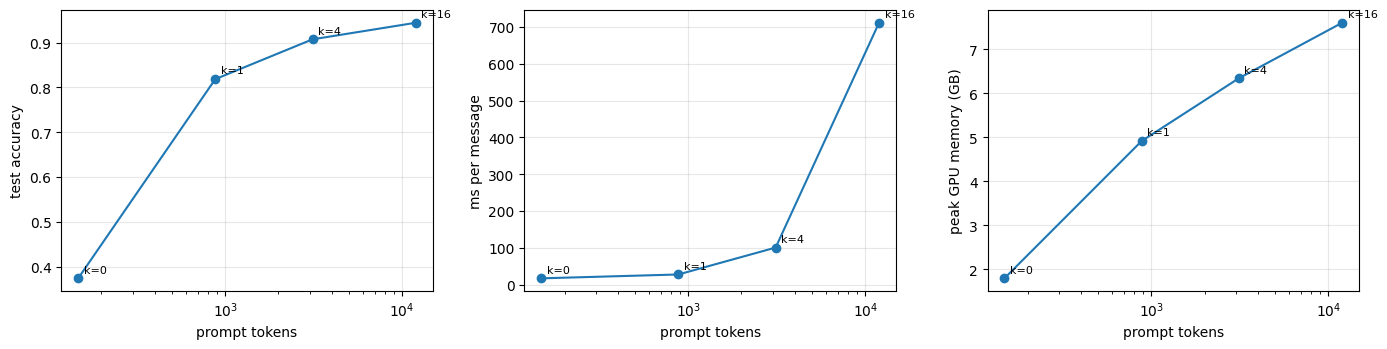

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
tokens = [r["tokens"] for r in FEW_SHOT]
for ax, key, label in zip(axes, ("accuracy", "ms", "peak_gb"),
                          ("test accuracy", "ms per message", "peak GPU memory (GB)")):
    ax.plot(tokens, [r[key] for r in FEW_SHOT], "o-")
    for r in FEW_SHOT:
        ax.annotate(f"k={r['k']}", (r["tokens"], r[key]), textcoords="offset points", xytext=(4, 4), fontsize=8)
    ax.set_xscale("log")
    ax.set_xlabel("prompt tokens")
    ax.set_ylabel(label)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Fine-tuning

Fine-tuning updates the model's weights using the examples. The cell trains LoRA adapters on 32 examples per intent (864 messages, 2 epochs) and routes the test set with no examples in the prompt.

In [11]:
from peft import LoraConfig
from trl import SFTConfig, SFTTrainer


def train_router(rows, label_map, lora_rank=16, full=False, epochs=2, lr=None, out="sft-run"):
    """Fine-tune the router on rows, whose intents are written with label_map.

    Each example is a prompt (system message and customer message) and a completion (the JSON
    answer); the loss is computed on the completion only. With full=False only LoRA adapters of
    rank lora_rank are trained; with full=True every weight is.
    """
    labels = sorted(set(label_map.values()))
    data = Dataset.from_list([
        {"prompt": build_prompt(r["text"], labels),
         "completion": json.dumps({"intent": label_map[r["intent"]]}) + tokenizer.eos_token}
        for r in rows
    ])
    model = AutoModelForCausalLM.from_pretrained(
        MODEL_ID, dtype=torch.bfloat16 if BF16 else torch.float32)
    # warmup_steps below 1 is a fraction of the training steps
    args = SFTConfig(
        output_dir=out, num_train_epochs=epochs, per_device_train_batch_size=8,
        gradient_accumulation_steps=2, learning_rate=lr or (2e-5 if full else 2e-4),
        lr_scheduler_type="cosine", warmup_steps=0.05, logging_steps=20, save_strategy="no",
        report_to="none", bf16=BF16, fp16=not BF16 and device == "cuda",
        gradient_checkpointing=full, completion_only_loss=True, disable_tqdm=True,
    )
    peft = None if full else LoraConfig(r=lora_rank, lora_alpha=2 * lora_rank, lora_dropout=0.05,
                                        target_modules="all-linear", task_type="CAUSAL_LM")
    trainer = SFTTrainer(model=model, args=args, train_dataset=data, peft_config=peft,
                         processing_class=tokenizer)
    start = time.perf_counter()
    trainer.train()
    model = trainer.model.merge_and_unload() if not full else trainer.model
    model = model.to(torch.bfloat16 if BF16 else torch.float16).eval()
    print(f"[INFO] trained on {len(rows):,} examples in {time.perf_counter() - start:.0f} s")
    return model


def sample_rows(per_intent, seed=SEED):
    r = random.Random(seed)
    return [row for intent in INTENTS for row in r.sample(POOL[intent], per_intent)]


REAL = {i: i for i in INTENTS}
del base
torch.cuda.empty_cache()
tuned = train_router(sample_rows(32), REAL)
tuned.save_pretrained("router-lora")  # used again in Part 2
texts, lengths, sec = route(tuned, [build_prompt(r["text"], INTENTS) for r in TEST])
SFT_RESULT = {**score(texts, truth), "tokens": float(np.mean(lengths)), "ms": 1000 * sec}
print(f"[INFO] fine-tuned, no examples: accuracy {SFT_RESULT['accuracy']:.3f}, "
      f"{SFT_RESULT['tokens']:.0f} prompt tokens, {SFT_RESULT['ms']:.1f} ms per message")
del tuned
torch.cuda.empty_cache()

{'loss': '0.1703', 'grad_norm': '1.219', 'learning_rate': '0.0001921', 'entropy': '0.07271', 'mean_token_accuracy': '0.9607', 'num_tokens': '5.01e+04', 'epoch': '0.3704'}
{'loss': '0.0359', 'grad_norm': '0.217', 'learning_rate': '0.0001526', 'entropy': '0.03603', 'mean_token_accuracy': '0.9886', 'num_tokens': '1.002e+05', 'epoch': '0.7407'}
{'loss': '0.01273', 'grad_norm': '0.00829', 'learning_rate': '9.384e-05', 'entropy': '0.00814', 'mean_token_accuracy': '0.9963', 'num_tokens': '1.504e+05', 'epoch': '1.111'}
{'loss': '0.00202', 'grad_norm': '0.1263', 'learning_rate': '3.731e-05', 'entropy': '0.005643', 'mean_token_accuracy': '0.9996', 'num_tokens': '2.005e+05', 'epoch': '1.481'}
{'loss': '0.002362', 'grad_norm': '0.1435', 'learning_rate': '3.817e-06', 'entropy': '0.005633', 'mean_token_accuracy': '0.9992', 'num_tokens': '2.506e+05', 'epoch': '1.852'}
{'train_runtime': '72.75', 'train_samples_per_second': '23.75', 'train_steps_per_second': '1.485', 'train_loss': '0.04181', 'entropy':

In [13]:
!pip install -U "torchao>=0.16.0"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 112.6 MB/s  0:00:00
  Attempting uninstall: torchao
    Found existing installation: torchao 0.10.0
    Uninstalling torchao-0.10.0:
      Successfully uninstalled torchao-0.10.0


### Position in a long context

A model with a 32,768-token window does not necessarily use every position in it equally well. Liu et al. found that language models answer best when the relevant information is at the start or the end of a long context, and worst when it is in the middle ([Lost in the Middle](https://arxiv.org/abs/2307.03172)). You test this on the base model and on the router you just fine-tuned. The router routes single messages almost perfectly, so a drop in its accuracy inside the inbox shows the effect of the long context. Instead of a single message, each model receives an inbox of messages, one of which is marked as the message to route.

**TODO 2.** Write `inbox_prompt`. It builds an inbox of `n_messages` messages, one per line, in which the message to route is placed at the relative `position` (0 for the first line, 0.5 for the middle, 1 for the last) and starts with the marker `[ROUTE THIS]`. The other messages are drawn from `DISTRACTORS`. The user turn is the inbox followed by `Route the message marked [ROUTE THIS].` The stub sends the target message alone.

In [12]:
DISTRACTORS = [row["text"] for intent in INTENTS for row in POOL[intent][-40:]]


def inbox_prompt(target_text, n_messages, position, seed=SEED):
    """Return the router prompt for an inbox of n_messages with the marked target at the given position."""
    # TODO 2: build the inbox with the marked target at the given position
    r = random.Random(seed)

    distractors = DISTRACTORS[:]

    r.shuffle(distractors)

    position = round(position * (n_messages - 1))

    target_text = f"[ROUTE THIS] {target_text}"

    inbox = distractors[:position] + [target_text] + distractors[position:(n_messages - 1)]

    inbox_text = "\n".join(inbox)

    return build_prompt(
        inbox_text + "\nRoute the message marked [ROUTE THIS].",
        INTENTS)

The cell routes 81 test messages (3 per intent) with each model, inside inboxes of 25, 100 and 400 messages, with the marked message at the start, in the middle and at the end, and prints the accuracy of each setting.

In [13]:
SUBSET = [r for intent in INTENTS for r in [x for x in TEST if x["intent"] == intent][:3]]
sub_truth = [r["intent"] for r in SUBSET]
SIZES, POSITIONS = (25, 100, 400), (0.0, 0.5, 1.0)
POSITION_ACC, POSITION_TOKENS = {}, {}
for name, path in [("base", MODEL_ID), ("fine-tuned router", "router-lora")]:
    model = load_model(path)
    single, _, _ = route(model, [build_prompt(r["text"], INTENTS) for r in SUBSET])
    POSITION_ACC[name] = np.zeros((len(SIZES), len(POSITIONS)))
    print(f"{name}: single message {score(single, sub_truth)['accuracy']:.3f}")
    for i, n in enumerate(SIZES):
        for j, pos in enumerate(POSITIONS):
            prompts = [inbox_prompt(r["text"], n, pos, seed=SEED + m) for m, r in enumerate(SUBSET)]
            texts, lengths, _ = route(model, prompts)
            POSITION_ACC[name][i, j] = score(texts, sub_truth)["accuracy"]
            POSITION_TOKENS[n] = float(np.mean(lengths))
        print(f"  {n:>4} messages ({POSITION_TOKENS[n]:>6.0f} tokens): "
              + "  ".join(f"position {p}: {a:.3f}" for p, a in zip(POSITIONS, POSITION_ACC[name][i])))
    del model
    torch.cuda.empty_cache()

base: single message 0.358
    25 messages (   426 tokens): position 0.0: 0.123  position 0.5: 0.099  position 1.0: 0.222
   100 messages (  1258 tokens): position 0.0: 0.123  position 0.5: 0.123  position 1.0: 0.284
   400 messages (  4582 tokens): position 0.0: 0.111  position 0.5: 0.086  position 1.0: 0.235
fine-tuned router: single message 0.963
    25 messages (   426 tokens): position 0.0: 0.568  position 0.5: 0.111  position 1.0: 0.778
   100 messages (  1258 tokens): position 0.0: 0.383  position 0.5: 0.222  position 1.0: 0.827
   400 messages (  4582 tokens): position 0.0: 0.160  position 0.5: 0.099  position 1.0: 0.778


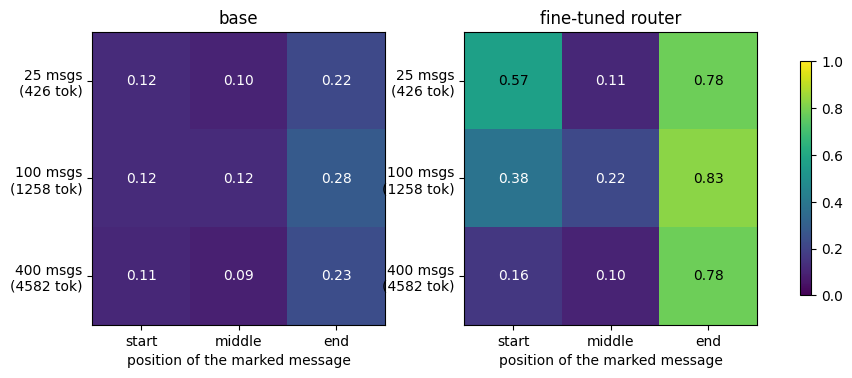

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, (name, acc) in zip(axes, POSITION_ACC.items()):
    im = ax.imshow(acc, cmap="viridis", vmin=0, vmax=1)
    ax.set_xticks(range(len(POSITIONS)))
    ax.set_xticklabels(["start", "middle", "end"])
    ax.set_yticks(range(len(SIZES)))
    ax.set_yticklabels([f"{n} msgs\n({POSITION_TOKENS[n]:.0f} tok)" for n in SIZES])
    for i in range(len(SIZES)):
        for j in range(len(POSITIONS)):
            ax.text(j, i, f"{acc[i, j]:.2f}", ha="center", va="center",
                    color="black" if acc[i, j] > 0.5 else "white")
    ax.set_xlabel("position of the marked message")
    ax.set_title(name)
fig.colorbar(im, ax=axes, shrink=0.8)
plt.show()

### Questions for Part 1

**Question 1.** How do accuracy, prompt length, time per message and peak memory change with the number of examples per intent? Which grows fastest, and why? Use your measured numbers.

As the number of examples per intent rises from 0 to 16, the accuracy, prompt length, time per message, and peak memory all increase.
The prompt length increases linearly. For example, when k = 0 the token prompts were 148 and it increases at k = 1 to 880 token prompts, k = 4 as 3,119 prompt tokens, and until k = 16 when there are 11,977 prompt tokens. It goes up about 732 tokens from k=0 to k=1 and about 743 tokens per k from k=1 to k=4.
The accuracy increases drastically from k = 0 and k = 1 about 0.449 and then it increases minimally from from k = 1 to k = 4 at about 0.088 and k = 4 to k = 16 at about 0.037. The accuracy caps at 1.0. This means that adding an additional example makes a smaller improvement.
The time per message grows faster than the prompt tokens because it starts out from 16.8 ms per message at k = 0  and it shoots up at k = 16 at 711.9 ms per message. Processing takes longer because the model has to process increasingly longer prompts.
The peak memory increases from k = 0 as 1.79 GB to k = 16 as 7.60 GB. This means it requires additional memory to process the larger prompts.
Prompt length grows the fastest. From k=0 to k=16 it increases about 81 times, while the measurements for time per message increases about 43 times. That is because every extra example adds a fixed chunk of tokens to the prompt. As the prompt gets longer, each additional token costs more than the last. The model reprocesses the entire prompt for every message and attention cost grows with the square of the prompt length. This shows the increase in the computational workload and the attention operations.


**Question 2.** Does the position of the marked message matter, and does the effect change with the size of the inbox? Compare the base model with the fine-tuned router, compare your results with the U-shaped curve of Liu et al., and explain any difference. Remember that the router was trained on single messages, never on inboxes.

The position of the marked message does matter. The measurements between the inboxes and their accuracy shows that the end position of the inboxes consistently have higher accuracy, such as ranging between 0.222 and 0.284 in the base router, compared to the first position and the middle position, which have similar low accuracies ranging from 0.099 to 0.123 in the base router. This also applies to the fine tuned model, since the end position of the inboxes at 1.0 yield higher values in the range of 0.778 to 0.827 compared to the first position that ranges from 0.160 to 0.568 and the middle position that ranges from 0.099 to 0.222.

For the base router, the effect doesn’t change with the size of the inboxes in the base. For example, the 25 messages inbox has the position 0.0 as 0.123, the 100 messages inbox has the position of 0.0 as 0.123, and the 400 messages has the position of 0.0 as 0.111. This shows there is no dependence between the inbox size and the accuracy of the positions because they all delve in the same range of 0.111 to 0.123. For the fine-tuned router, the effect does change with the size of the inboxes at the base. For example, the start position declines as inbox size increases, falling from 0.568 with 25 messages to 0.160 with 400 messages, even though the performance of the model towards the end position remains relatively consistent as the inbox size increases at the range of 0.778 to 0.827. This suggests that larger inboxes particularly hurt the router's ability to identify messages near the beginning, while its performance at the end remains relatively stable.
Liu et al. found that models answer best from information at the start or the end of a long context (Liu et al., 2023). Their experiments found that performance was generally higher when relevant information appeared at the beginning or end and lower when it appeared in the middle. This produced the U-shaped curve. The base router performs better at the end than in the middle, but there is no strong evidence of a typical U-shaped curve based on the position and accuracy. Although the 25 messages inbox and the 400 messages inbox shows the starting position and the ending position accuracies that are higher than the middle, the start and middle accuracy are almost identical for the 100 messages inbox at 0.123. For the fine tuned router, there is a clear U-shaped pattern with all of the starting accuracies high compared with the middle and the ending accuracies are higher than the middle in all of the inbox messages. However, the U-shaped curve is asymmetric because the end position performs considerably better than the beginning instead of within its same range.

**Question 3.** The fine-tuned router uses a short prompt. Compare it with the best few-shot setting on accuracy and on cost per message. If the support desk routes one million messages a day, which would you deploy, and what would change your mind?

The fine-tuned router achieves 98.5% accuracy, which outperforms the k=16 examples per intent for the few-shot setting that achieves 94.4%. However, the fine-tuned router accuracy dropped from 0.568 for 25 messages to 0.160 for 400 messages. In comparison, the base model remains relatively consistent. For messages in the middle, both models perform poorly, with accuracy ranging from 0.086 to 0.222. For a support desk processing one million messages per day, the difference becomes substantial. The few-shot approach requires approximately 202 GPU-hours per day, compared with only 4.6 GPU-hours for the fine-tuned router. Additionally, fine-tuning took only 73 seconds on 864 training examples, making the initial training cost relatively small. I would deploy the fine-tuned router because it provides higher accuracy, lower inference costs, and better scalability for processing large volumes of individual messages. However, I would reconsider this decision if the intent categories changed frequently, since new or modified intents could require retraining. The fine-tuned router performs poorly when identifying messages buried within longer inboxes, achieving only approximately 0.10–0.22 accuracy for middle-position messages. Therefore, I would deploy it to process one message per call rather than entire inboxes.


## Part 2: thinking tokens

With `enable_thinking=True`, Qwen3 first writes its reasoning between `<think>` and `</think>` and then the answer. Reasoning can help on problems that need several steps. It also uses more tokens. Each generated token adds GPU time and, behind an API, cost. The cell below generates with thinking on and off for 135 test messages (5 per intent), with the sampling settings that the Qwen3 model card recommends for each mode and a limit of 1,024 new tokens.

**TODO 3.** Write `split_thinking`, which takes a generated text and returns the number of reasoning tokens and the answer. The reasoning is the text up to and including `</think>`, and the answer is the text after it. If `</think>` never appears, the answer is the whole text. The model then either did not reason, as with thinking off (Qwen3 puts the empty `<think></think>` block in the prompt, so the output has no tags), or opened a `<think>` block that the token limit cut off. Count the whole text as reasoning only in the second case; otherwise the reasoning count is 0. The stub treats the whole text as the answer.

In [19]:
def split_thinking(text):
    """Return (reasoning_tokens, answer_text) for one generated text."""
    text = text.strip()

    if "</think>" in text:
        reasoning, answer = text.split("</think>", 1)
        reasoning_tokens = len(tokenizer.encode(reasoning + "</think>"))
        return reasoning_tokens, answer.strip()

    if "<think>" in text:
        return len(tokenizer.encode(text)), ""

    return 0, text

In [25]:
THINK_SUBSET = [r for intent in INTENTS for r in [x for x in TEST if x["intent"] == intent][:5]]
think_truth = [r["intent"] for r in THINK_SUBSET]


def think_prompt(text, thinking):
    messages = [{"role": "system", "content": system_prompt(INTENTS)}, {"role": "user", "content": text}]
    return tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True,
                                         enable_thinking=thinking)


@torch.no_grad()
def generate_mode(model, thinking, batch_size=16, max_new_tokens=1024):
    torch.manual_seed(SEED)
    sampling = dict(temperature=0.6, top_p=0.95, top_k=20) if thinking else dict(temperature=0.7, top_p=0.8, top_k=20)
    prompts = [think_prompt(r["text"], thinking) for r in THINK_SUBSET]
    texts, new_tokens = [], []
    start = time.perf_counter()
    for i in range(0, len(prompts), batch_size):
        batch = tokenizer(prompts[i:i + batch_size], return_tensors="pt", padding=True).to(device)
        out = model.generate(**batch, max_new_tokens=max_new_tokens, do_sample=True,
                             pad_token_id=tokenizer.pad_token_id, **sampling)
        gen = out[:, batch["input_ids"].shape[1]:]
        texts += tokenizer.batch_decode(gen, skip_special_tokens=True)
        new_tokens += (gen != tokenizer.pad_token_id).sum(1).tolist()
    sec = (time.perf_counter() - start) / len(prompts)
    reasoning, answers = zip(*[split_thinking(t) for t in texts])
    return {**score(list(answers), think_truth), "new_tokens": float(np.mean(new_tokens)),
            "reasoning_tokens": float(np.mean(reasoning)), "cut_off": float(np.mean([n >= max_new_tokens for n in new_tokens])),
            "ms": 1000 * sec, "example": texts[0]}


THINKING = {}
for label, path in [("base", MODEL_ID), ("fine-tuned router", "router-lora")]:
    model = load_model(path)
    for thinking in (False, True):
        r = generate_mode(model, thinking)
        THINKING[(label, thinking)] = r
        print(f"{label:<16} thinking={str(thinking):<5} accuracy {r['accuracy']:.3f}  valid JSON {r['valid_json']:.3f}  "
              f"new tokens {r['new_tokens']:>6.1f}  reasoning tokens {r['reasoning_tokens']:>6.1f}  "
              f"cut off {r['cut_off']:.2f}  {r['ms']:>7.1f} ms per message")
    del model
    torch.cuda.empty_cache()

base             thinking=False accuracy 0.326  valid JSON 1.000  new tokens    8.6  reasoning tokens    0.0  cut off 0.00     32.2 ms per message
base             thinking=True  accuracy 0.504  valid JSON 0.993  new tokens  199.5  reasoning tokens  190.0  cut off 0.01   1569.4 ms per message
fine-tuned router thinking=False accuracy 0.985  valid JSON 1.000  new tokens    8.4  reasoning tokens    0.0  cut off 0.00     31.0 ms per message
fine-tuned router thinking=True  accuracy 0.956  valid JSON 1.000  new tokens   86.8  reasoning tokens   77.4  cut off 0.00    854.8 ms per message


In [21]:
print(split_thinking('{"intent": "cancel_order"}'))
print(split_thinking('<think>hmm</think>{"intent": "cancel_order"}'))
print(split_thinking('<think>hmm, still going'))

(0, '{"intent": "cancel_order"}')
(4, '{"intent": "cancel_order"}')
(6, '')


In [23]:
print(repr(THINKING[("base", False)]["example"]))

'{"intent": "check_cancellation_fee"}'


In [24]:
print(split_thinking(THINKING[("base", False)]["example"]))

(0, '{"intent": "check_cancellation_fee"}')


### Questions for Part 2

**Question 4.** For the base model, does thinking improve the routing accuracy? Compare the gain, if any, with the cost in generated tokens and time per message, and estimate the cost of routing one million messages a day in each mode.

The thinking = True and thinking = False accuracies in the base model shows the thinking improves the routing accuracy since the accuracy goes from 0.326 to 0.504. However, it has a high cost as a result as it goes from 8.6 to 199.5, almost 23 times the generated tokens and the time taken goes from 32.2 ms per message to 1,569.4 ms per message, which is 49 times more time. For the fine-tuned router it gives no benefit since the accuracy decreases from 0.985 without thinking to 0.956 with thinking, while costing about 10 times more tokens as it goes from 8.4 to 86.8 and 28 times more time as it goes from 31.0 to 854.8. At one million messages per day, the base model needs about 8.9 GPU-hours without thinking and about 436 with thinking, and generates about 8.6 million versus 199.5 million tokens. The fine-tuned router needs about 8.6 GPU-hours without thinking and about 237 with thinking, and generates about 8.4 million versus 86.8 million tokens.


**Question 5.** The router of Part 1 was fine-tuned on answers without reasoning. What happens when you turn thinking on for it? Explain from the training data and the chat template what the fine-tuning did to the model's reasoning behavior.

Turning thinking on doesn't help the fine-tuned router. It scores 0.956 with thinking and 0.985 without, a gap of about four messages that is within noise. Meanwhile it generates 86.8 tokens instead of 8.4 and takes 854.8 ms per message instead of 31.0. The cause is how it was trained. Every training answer was a short JSON label with no reasoning, so the router learned to answer straight away. With thinking off, the chat template closes the think block, which matches that format. With thinking on, the template leaves the block open, something the router never saw in training, so it falls back on the base model’s habit of reasoning first. Fine-tuning didn't erase that habit, because LoRA only changes a small set of weights. The router still writes about 77 reasoning tokens, though that's well under the base model's 190, since training pushed it hard to give the label immediately. Its decision boundaries are already in the weights, so the extra reasoning adds cost and nothing else.

**Question 6.** Name a kind of support message, or a change to the task, for which you would expect reasoning to help. Explain why, and how you would test it.

A kind of message where reasoning should help with conditional messages, where the correct label depends on combining several facts. A <think> block lets the model write out the candidates, compare them and then choose. Reasoning has the most room to help where the confusions are semantic. The base model, which has no task knowledge in its weights, gained from reasoning (about 0.37 to 0.50 on the subset), and its errors were confusions between neighbouring intents such as cancel_order, check_cancellation_fee and complaint. It should help much less for the fine-tuned router on ordinary single-intent messages, because fine-tuning already puts the decision boundaries into the weights. To test whether thinking helps on ambiguous messages, I would start by building a harder test set of about 100 messages, each with two or more plausible intents. I would label every message with its primary intent and have a second person label a sample, to check that the labels are consistent. The original single-intent TEST subset would stay in as a control. Then I would rerun the same comparison as before, with the base and fine-tuned models, thinking on and off, using the same prompts, sampling settings and max_new_tokens. For each run I would record accuracy, valid JSON rate, generated tokens, cut-off rate and average time per message. The main thing I would look at is how much thinking improves accuracy on each set. My hypothesis is that the improvement will be bigger on the ambiguous set than on the control. If the improvement is about the same on both, thinking has no special advantage for resolving ambiguous intents. I would also check that the result is reliable. A hundred messages may be too few to detect a small difference, so I would use more messages, report confidence intervals, or run a paired test on the messages where the two modes disagree. Next, I would read a sample of the reasoning traces to see whether the model really names the competing intents before it answers, or just restates the message. Finally, I would weigh the cost. If thinking gained 8 percentage points but took 50 times longer, I would compare it against a cheaper option, such as fine-tuning the router on multi-intent examples, to see whether a similar gain is possible at much lower cost.


## References

* Brown et al., [Language Models are Few-Shot Learners](https://arxiv.org/abs/2005.14165), 2020.
* Hsieh et al., [RULER: What's the Real Context Size of Your Long-Context Language Models?](https://arxiv.org/abs/2404.06654), 2024.
* Hu et al., [LoRA: Low-Rank Adaptation of Large Language Models](https://arxiv.org/abs/2106.09685), 2021.
* Liu et al., [Lost in the Middle: How Language Models Use Long Contexts](https://arxiv.org/abs/2307.03172), 2023.
* Mosbach et al., [Few-shot Fine-tuning vs. In-context Learning: A Fair Comparison and Evaluation](https://arxiv.org/abs/2305.16938), 2023.
* Qwen Team, [Qwen3 Technical Report](https://arxiv.org/abs/2505.09388), 2025.
* Sprague et al., [To CoT or Not to CoT? Chain-of-Thought Helps Mainly on Math and Symbolic Reasoning](https://arxiv.org/abs/2409.12183), 2024.
* Wei et al., [Chain-of-Thought Prompting Elicits Reasoning in Large Language Models](https://arxiv.org/abs/2201.11903), 2022.